# Lab 13-04 · Maxwell's Equations and Time-Varying Fields

Companion to [chapter 13-04](../../chapters/13-04-maxwells-equations.md). Four parts: solving Maxwell's two curl equations directly by the finite-difference time-domain (FDTD) method and watching a pulse travel at the speed of light; the numerical phase velocity of the FDTD grid; a pulse meeting a conducting slab; and the Poynting theorem and the conductor–dielectric ratio $\sigma/\omega\varepsilon$. Run the cells in order.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
eps0, mu0 = 8.8541878128e-12, 4e-7 * math.pi
c0 = 1 / math.sqrt(mu0 * eps0)

## Part 1 · Maxwell's curls on a grid

In one dimension, with $E_z$ and $H_y$ depending only on $x$ and $t$, Faraday and Ampère–Maxwell reduce to

$$
\mu_0\frac{\partial H_y}{\partial t} = \frac{\partial E_z}{\partial x}, \qquad \varepsilon_0\frac{\partial E_z}{\partial t} = \frac{\partial H_y}{\partial x}.
$$

The Yee scheme stores $E$ and $H$ on interleaved grids, half a cell and half a time step apart, and updates each from the other's spatial difference. Nothing about waves or the speed of light is programmed in; only the two curl equations. We use normalized units (cell size 1, $c$ = 1, so $\eta_0$ = 1) and a Courant number $S = c\,\Delta t/\Delta x$ = 0.5.

**Predict first:** a Gaussian pulse of $E_z$ alone starts at cell 200, at rest. Where will it be after 600 time steps? (Hint: with no $H$ to give it a direction, it splits.)

two half-height pulses; the right-going peak after 600 steps is at cell 500 with height 0.500: moved 300 cells in 300 cell-transit times -> speed 1.0000 c


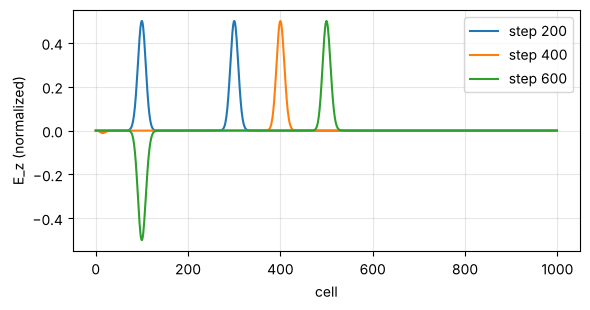

In [2]:
def fdtd(ncell=1000, nsteps=600, S=0.5, src=200, loss=None, snapshot_steps=(), one_way=False):
    ez, hy = np.zeros(ncell), np.zeros(ncell - 1)
    loss = np.zeros(ncell) if loss is None else loss          # sigma * dt / (2 eps) in each cell
    ca, cb = (1 - loss) / (1 + loss), S / (1 + loss)
    x = np.arange(ncell)
    ez[:] = np.exp(-((x - src) / 12.0) ** 2)
    if one_way:                                                # matching H (H = -E for a right-going wave, eta = 1),
        hy[:] = -np.exp(-((x[:-1] + 0.5 + S / 2 - src) / 12.0) ** 2)  # placed half a cell and half a step away

    snaps = {}
    for n in range(1, nsteps + 1):
        hy += S * (ez[1:] - ez[:-1])
        ez[1:-1] = ca[1:-1] * ez[1:-1] + cb[1:-1] * (hy[1:] - hy[:-1])
        if n in snapshot_steps:
            snaps[n] = ez.copy()
    return ez, snaps

ez, snaps = fdtd(nsteps=600, snapshot_steps=(200, 400, 600))
right = np.argmax(ez[200:]) + 200
print(f"two half-height pulses; the right-going peak after 600 steps is at cell {right} with height {ez[right]:.3f}: "
      f"moved {right - 200} cells in {600 * 0.5:.0f} cell-transit times -> speed {(right - 200) / 300:.4f} c")
fig, ax = plt.subplots(figsize=(6, 3.2))
for n, e in snaps.items():
    ax.plot(e, label=f'step {n}')
ax.set_xlabel('cell'); ax.set_ylabel('E_z (normalized)'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 2 · The grid's phase velocity

A grid is not quite vacuum: short wavelengths travel slightly slower than $c$. Drive a sinusoid with $N$ cells per wavelength, measure the phase advance from cell to cell, and compare with the Yee dispersion relation $\sin(\omega\Delta t/2)/(c\Delta t) = \sin(k\Delta x/2)/\Delta x$.

**Predict first:** at 20 cells per wavelength and $S$ = 0.5, is the wave faster or slower than $c$, and by roughly how much? What happens at $S$ = 1?

S = 0.5, 10 cells/wavelength: FDTD 0.98726 c, dispersion relation 0.98759 c
S = 0.5, 20 cells/wavelength: FDTD 0.99689 c, dispersion relation 0.99691 c
S = 0.5, 40 cells/wavelength: FDTD 0.99923 c, dispersion relation 0.99923 c
S = 1.0, 10 cells/wavelength: FDTD 1.00000 c, dispersion relation 1.00000 c
S = 1.0, 20 cells/wavelength: FDTD 1.00000 c, dispersion relation 1.00000 c
S = 1.0, 40 cells/wavelength: FDTD 1.00001 c, dispersion relation 1.00000 c


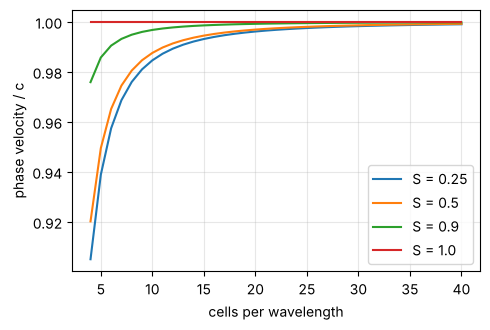

In [3]:
def phase_velocity_fdtd(cpw, S, ncell=1500):
    # stop before the reflection from the far end (fixed E = 0) returns to the probe cells
    omega = 2 * math.pi / cpw
    nsteps = int(1100 / S)
    ez, hy = np.zeros(ncell), np.zeros(ncell - 1)
    probe = np.arange(200, 700)
    acc = np.zeros(len(probe), dtype=complex)
    for n in range(nsteps):
        hy += S * (ez[1:] - ez[:-1])
        ez[1:-1] += S * (hy[1:] - hy[:-1])
        ez[37] += math.sin(omega * n * S) * min(1.0, n * S / 60)   # cell 37: the echo off the left wall must not cancel the wave
        if n > nsteps - int(4 * cpw / S):
            acc += ez[probe] * np.exp(-1j * omega * n * S)
    k = -np.polyfit(probe, np.unwrap(np.angle(acc)), 1)[0]
    return omega / k

def phase_velocity_theory(cpw, S):
    kdx = 2 * math.pi / cpw
    return 2 * math.asin(S * math.sin(kdx / 2)) / (S * kdx)

for S in (0.5, 1.0):
    for cpw in (10, 20, 40):
        print(f"S = {S}, {cpw:2d} cells/wavelength: FDTD {phase_velocity_fdtd(cpw, S):.5f} c, dispersion relation {phase_velocity_theory(cpw, S):.5f} c")
cpws = np.arange(4, 41)
fig, ax = plt.subplots(figsize=(5, 3.4))
for S in (0.25, 0.5, 0.9, 1.0):
    ax.plot(cpws, [phase_velocity_theory(n, S) for n in cpws], label=f'S = {S}')
ax.set_xlabel('cells per wavelength'); ax.set_ylabel('phase velocity / c'); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Part 3 · A pulse meets a conductor

Launch a one-way pulse (with the matching $H$, so it only travels right) toward cells 600 to 700, which have a conductivity. In the update, conduction current enters through the factor $\sigma\Delta t/2\varepsilon$. A weak conductor attenuates the pulse as it passes; a strong one reflects most of it with an inverted electric field, just as a short circuit does at the end of a transmission line (13-06, 13-07).

**Predict first:** for the strong conductor, what sign will the reflected pulse's $E_z$ have?

weak conductor: reflected peak -0.039 at cell 518; transmitted peak +0.672 at cell 700
strong conductor: reflected peak -0.762 at cell 502; transmitted peak +0.000 at cell 700


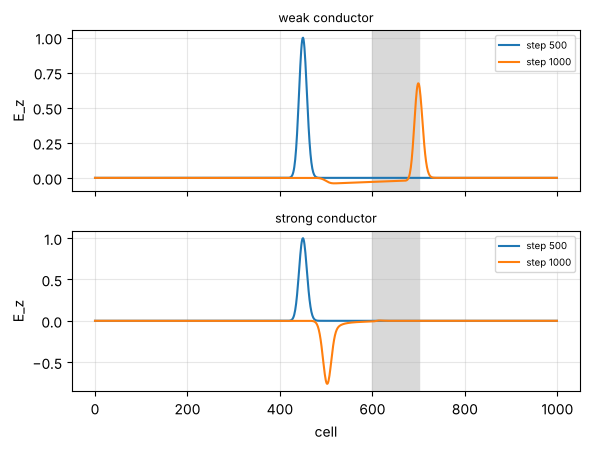

In [4]:
fig, axes = plt.subplots(2, 1, figsize=(6, 4.6), sharex=True)
for ax, sigma_term, label in zip(axes, (0.002, 0.5), ('weak conductor', 'strong conductor')):
    loss = np.zeros(1000); loss[600:700] = sigma_term
    ez, snaps = fdtd(nsteps=1000, loss=loss, snapshot_steps=(500, 1000), one_way=True)
    for n, e in snaps.items():
        ax.plot(e, label=f'step {n}')
    ax.axvspan(600, 700, color='0.85'); ax.set_title(label, fontsize=9); ax.set_ylabel('E_z'); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    e = snaps[1000]
    i_ref = np.argmax(np.abs(e[:600])); i_tr = np.argmax(np.abs(e[700:])) + 700
    print(f"{label}: reflected peak {e[i_ref]:+.3f} at cell {i_ref}; transmitted peak {e[i_tr]:+.3f} at cell {i_tr}")
axes[-1].set_xlabel('cell'); plt.tight_layout(); plt.show()

## Part 4 · Poynting and σ/ωε

First, the Poynting theorem for the wire of Example 13-04.5: integrate $\vec{E}\times\vec{H}$ over the wire's surface and compare with $I^2R$. Then plot the ratio of conduction to displacement current against frequency for several materials.

Poynting inflow 0.5488 W, I^2 R 0.5488 W


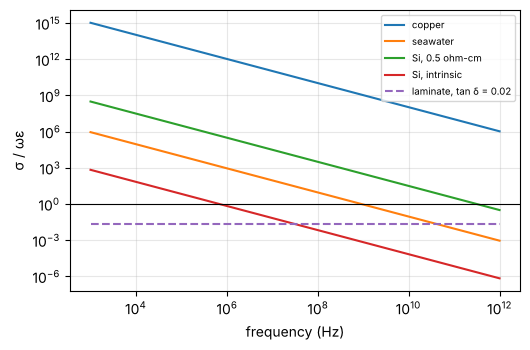

In [5]:
a, I, L, sigma = 1e-3, 10.0, 1.0, 5.8e7
R = L / (sigma * math.pi * a**2)
E, H = I * R / L, I / (2 * math.pi * a)
print(f"Poynting inflow {E * H * 2 * math.pi * a * L:.4f} W, I^2 R {I**2 * R:.4f} W")
f = np.logspace(3, 12, 400)
materials = {'copper': (5.8e7, 1), 'seawater': (4.0, 81), 'Si, 0.5 ohm-cm': (200.0, 11.7), 'Si, intrinsic': (1 / 2.3e3, 11.7)}
fig, ax = plt.subplots(figsize=(5.4, 3.6))
for name, (s, er) in materials.items():
    ax.loglog(f, s / (2 * math.pi * f * er * eps0), label=name)
ax.loglog(f, np.full_like(f, 0.02), '--', label='laminate, tan δ = 0.02')
ax.axhline(1, color='k', lw=0.8)
ax.set_xlabel('frequency (Hz)'); ax.set_ylabel('σ / ωε'); ax.legend(fontsize=7); ax.grid(True, which='major', alpha=0.3)
plt.tight_layout(); plt.show()

## What to notice

- The pulse moves at one cell per $1/S$ steps, the speed of light in grid units, although only the two curl equations were coded: waves are a consequence of Maxwell's equations.
- The grid is slightly dispersive: at 20 cells per wavelength and $S$ = 0.5 the phase velocity is 0.9969 $c$. At $S$ = 1 (the "magic time step") one-dimensional FDTD is exact.
- A conductor reflects with an inverted electric field, because the field must nearly vanish inside it.
- Each material's line crosses 1 at $f = 1/(2\pi\tau_r)$: below it the material conducts, above it the displacement current wins.